In [4]:
import pandas as pd
df = pd.read_excel("../data/SalesCRM.xlsx")
print("Target data type:")
print(df["Subscribed"].dtype)

print("\nUnique target values:")
print(df["Subscribed"].unique())

print("\nTarget value counts:")
print(df["Subscribed"].value_counts(dropna=False))

print("\nNumber of unique values:")
print(df["Subscribed"].nunique(dropna=True))

/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Cell K355 is marked as a date but the serial value 6691845.0 is outside the limits for dates. The cell will be treated as an error.
  for idx, row in parser.parse():


Target data type:
object

Unique target values:
[nan datetime.datetime(2022, 4, 16, 0, 0)
 datetime.datetime(2022, 4, 27, 0, 0) datetime.datetime(2022, 4, 18, 0, 0)
 datetime.datetime(2022, 4, 7, 0, 0) datetime.datetime(2022, 2, 21, 0, 0)
 datetime.datetime(2022, 2, 25, 0, 0) datetime.datetime(2022, 3, 14, 0, 0)
 datetime.datetime(2022, 2, 8, 0, 0) datetime.datetime(2022, 1, 31, 0, 0)
 datetime.datetime(2022, 2, 12, 0, 0) datetime.datetime(2022, 1, 15, 0, 0)
 datetime.datetime(2021, 12, 26, 0, 0)
 datetime.datetime(2021, 12, 30, 0, 0)
 datetime.datetime(2022, 1, 16, 0, 0) datetime.datetime(2021, 12, 8, 0, 0)
 datetime.datetime(2021, 11, 21, 0, 0)
 datetime.datetime(2021, 10, 28, 0, 0)
 datetime.datetime(2021, 11, 22, 0, 0)
 datetime.datetime(2020, 10, 1, 0, 0)
 datetime.datetime(2020, 11, 11, 0, 0)
 datetime.datetime(2020, 9, 15, 0, 0)
 datetime.datetime(2021, 12, 14, 0, 0)
 datetime.datetime(2021, 7, 18, 0, 0) datetime.datetime(2021, 6, 28, 0, 0)
 datetime.datetime(2021, 5, 23, 0, 0) 

In [4]:
import pandas as pd

from feature_selection import FeatureSelector
from rl_environment import FeatureSelectionEnvironment
from qlearningagent import QLearningAgent

# Load CRM dataset.
df = pd.read_excel("../data/SalesCRM.xlsx")

# Prepare features.
selector = FeatureSelector(
    df,
    target="Subscribed",
    exclude_columns=["Id"],
)

X, y = selector.prepare_data()

print("Target distribution:")
print(y.value_counts(dropna=False))

print("\nTarget data type:")
print(y.dtype)

print("\nUnique target values:")
print(y.unique())

print("\nNumber of records:", len(y))

print("Number of features:", selector.get_feature_count())
print("Features:", selector.get_feature_names())

# Initialize RL environment.
environment = FeatureSelectionEnvironment(
    X=X,
    y=y,
    max_features=15,
)

# Initialize Q-learning agent.
agent = QLearningAgent(
    n_actions=environment.n_actions
)

results = agent.train(
    environment,
    episodes=100
)

# Extract results.
best_state = results["best_state"]
best_reward = results["best_reward"]
episode_rewards = results["episode_rewards"]
epsilon_history = results["epsilon_history"]

print("Best state:", best_state)
print("Best reward:", best_reward)
print("Final epsilon:", epsilon_history[-1])

# Train agent.
#best_state, best_reward, episode_rewards, epsilon_history = agent.train(
#    environment,
#    episodes=100,
#)

print("Best state:", best_state)
print("Best reward:", best_reward)

/opt/anaconda3/lib/python3.13/site-packages/openpyxl/worksheet/_read_only.py:85: UserWarning: Cell K355 is marked as a date but the serial value 6691845.0 is outside the limits for dates. The cell will be treated as an error.
  for idx, row in parser.parse():


Dataset shape: (11032, 12)

Target distribution:
Subscribed
0    10985
1       47
Name: count, dtype: int64
Target distribution:
Subscribed
0    10985
1       47
Name: count, dtype: int64

Target data type:
int64

Unique target values:
[0 1]

Number of records: 11032
Number of features: 12
Features: ['ID', 'Country', 'Education', 'First Contact', 'Last Contact', 'Status', 'Stage', 'First Call', 'Signed up for a demo', 'Filled in customer survey', 'Did sign up to the platform', 'Account Manager assigned']
Episode 10/100 | Reward: 23.2342 | Best: 0.9872 | Epsilon: 0.9511
Episode 20/100 | Reward: 21.0536 | Best: 0.9872 | Epsilon: 0.9046
Episode 30/100 | Reward: 2.7699 | Best: 0.9872 | Epsilon: 0.8604
Episode 40/100 | Reward: 18.6144 | Best: 0.9887 | Epsilon: 0.8183
Episode 50/100 | Reward: 18.9796 | Best: 0.9887 | Epsilon: 0.7783
Episode 60/100 | Reward: 22.5507 | Best: 0.9887 | Epsilon: 0.7403
Episode 70/100 | Reward: 3.4316 | Best: 0.9887 | Epsilon: 0.7041
Episode 80/100 | Reward: 14.47

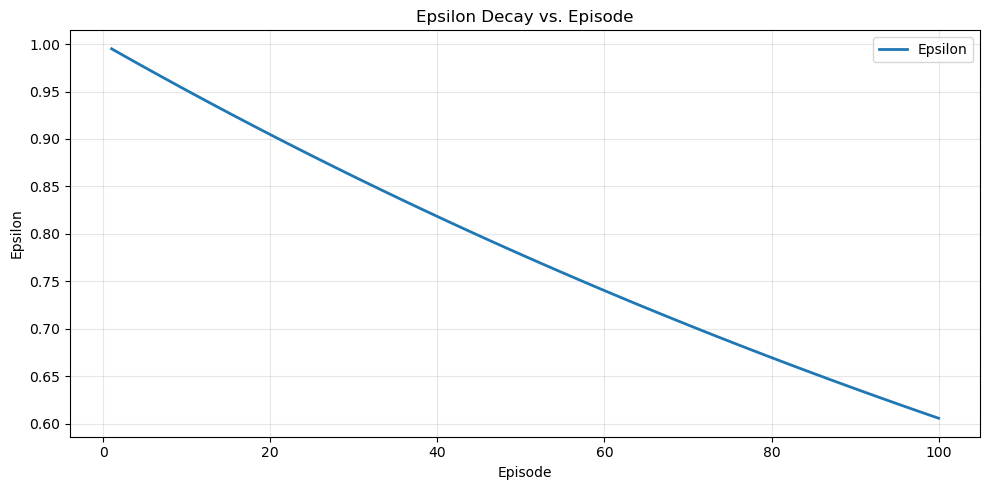

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(epsilon_history) + 1),
    epsilon_history,
    label="Epsilon",
    linewidth=2
)

plt.xlabel("Episode")
plt.ylabel("Epsilon")
plt.title("Epsilon Decay vs. Episode")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

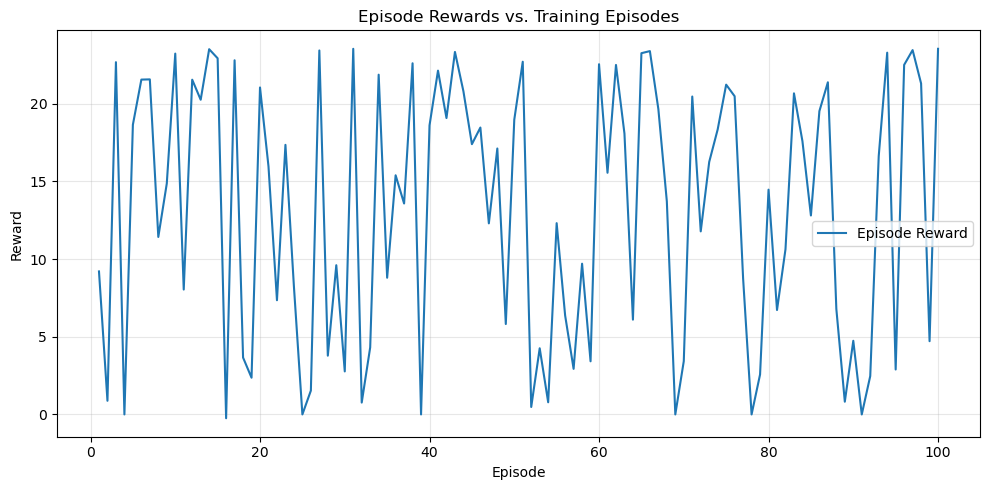

In [7]:
import matplotlib.pyplot as plt

# Extract training metrics.
episode_rewards = results["episode_rewards"]
epsilon_history = results["epsilon_history"]

episodes = range(1, len(episode_rewards) + 1)

# Plot episode rewards.
plt.figure(figsize=(10, 5))

plt.plot(
    episodes,
    episode_rewards,
    label="Episode Reward",
    linewidth=1.5
)

plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("Episode Rewards vs. Training Episodes")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:

from evaluate import ModelEvaluator

# 1. Retrieve the best state from training results.
best_state = results["best_state"]
best_reward = results["best_reward"]

# 2. Convert the best binary state into selected feature names.
feature_names = selector.get_feature_names()

best_features = [
    feature
    for feature, selected in zip(feature_names, best_state)
    if selected == 1 and feature != "ID"
]

print("Best reward:", best_reward)
print("Selected features:", best_features)

# 3. Validate feature selection.
if not best_features:
    raise ValueError(
        "Q-learning did not select any valid features."
    )

print("Number of selected features:", len(best_features))

# 4. Initialize evaluator.
evaluator = ModelEvaluator(X, y)

# 5. Compare RL-selected features against all features.
comparison_results, baseline_model, rl_model = (
    evaluator.compare_features(best_features)
)

# 6. Display model comparison.
print("\nModel Performance Comparison:")
print(comparison_results.to_string(index=False))

# 7. Calculate feature reduction.
total_features = X.shape[1]
selected_count = len(best_features)

reduction = (
    (total_features - selected_count)
    / total_features
) * 100

print(f"\nOriginal feature count: {total_features}")
print(f"Selected feature count: {selected_count}")
print(f"Feature reduction: {reduction:.2f}%")


Best reward: 0.991476987862297
Selected features: ['Stage', 'Did sign up to the platform']
Number of selected features: 2

Model Performance Comparison:
               Model  Accuracy  Precision  Recall  F1 Score  ROC-AUC   PR-AUC  Number of Features
        All Features  0.998641   0.750000     1.0  0.857143 0.999949 0.988889                  12
RL Selected Features  0.999094   0.818182     1.0  0.900000 0.999949 0.979798                   2

Original feature count: 12
Selected feature count: 2
Feature reduction: 83.33%
